# 04 · Nivel 2 y cascada completa con enrutamiento suave

Hasta aquí: la Etapa 0 resuelve portero vs. campo (100%) y el Nivel 1 clasifica en bloques con probabilidades bien calibradas. Ahora se construye el Nivel 2 y se evalúa la cascada de extremo a extremo.

**Diseño**

- **Clases finales (9):** Central, Lateral, Carrilero, Pivote, Interior, Mediapunta, Mediocampista de banda, Extremo y Delantero centro. Los pares izquierda/derecha están fusionados (el notebook 03 mostró que no se distinguen) y CF se funde con ST (solo 26 jugadores en prueba).
- **Nivel 1:** Fisher + KNN sobre los **bloques**.
- **Nivel 2:** un submodelo por bloque con **SFS + KNN**, cada uno con sus propias métricas.
- **Enrutamiento suave:** `P(clase) = Σ P(bloque) · P(clase | bloque)`. Se compara con el enrutamiento duro (solo el bloque más probable).
- **Taxonomía como parámetro:** A (Defensa / Medio / Delantero) y B (con bloque Banda) usan **las mismas 9 clases finales** y solo cambian los bloques, así que se comparan en igualdad de condiciones.

**Evaluación (jugadores de campo; la compuerta ya es 100%):** top-1, top-2 y top-3 sobre la posición principal, log-loss, y acierto flexible con las posiciones secundarias. Como referencia, dos modelos **planos** que clasifican las 9 clases de una sola vez: Fisher + KNN y Random Forest.

> Ejecutarlo completo toma varios minutos (selección de métricas con validación cruzada).

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score

from src.models.cascada import Cascada
from src.models.nivel1 import FisherKNN, curva_k_fisher
from src.models.metricas import elegir_k

sns.set_theme(style="whitegrid")

SEED = 42
PROC = Path("..") / "data" / "processed"
ID_COLS = ["player_id", "short_name", "posicion_principal", "y_gen", "player_positions"]

df = pd.read_csv(PROC / "jugadores_procesados.csv")
try:
    posiciones = pd.read_csv(PROC / "posiciones_jugadores.csv")
except FileNotFoundError:
    raise FileNotFoundError("Falta posiciones_jugadores.csv: ejecuta `python src/data/make_dataset.py`")
df = df.merge(posiciones, on="player_id", how="left")

metricas = [c for c in df.columns if c not in ID_COLS]
portero_cols = [c for c in metricas if c.startswith("goalkeeping_")]
metricas_campo = [c for c in metricas if c not in portero_cols]
print(f"{len(df):,} jugadores · {len(metricas_campo)} métricas de campo")

18,350 jugadores · 37 métricas de campo


## 1. Taxonomía: posiciones → clases finales → bloques

`MAPA_CLASE` fusiona posiciones en clases finales (igual para A y B). `BLOQUES` dice a qué bloque pertenece cada clase en cada taxonomía; la única diferencia es dónde viven `Extremo` y `Mediocampista de banda`.

In [2]:
MAPA_CLASE = {
    "CB": "Central",
    "LB": "Lateral", "RB": "Lateral",
    "LWB": "Carrilero", "RWB": "Carrilero",
    "CDM": "Pivote", "CM": "Interior", "CAM": "Mediapunta",
    "LM": "Mediocampista de banda", "RM": "Mediocampista de banda",
    "LW": "Extremo", "RW": "Extremo",
    "ST": "Delantero centro", "CF": "Delantero centro",
}
ORDEN = ["Central", "Lateral", "Carrilero", "Pivote", "Interior", "Mediapunta",
         "Mediocampista de banda", "Extremo", "Delantero centro"]

BLOQUES = {
    "A": {"Central": "Defensa", "Lateral": "Defensa", "Carrilero": "Defensa",
          "Pivote": "Medio", "Interior": "Medio", "Mediapunta": "Medio",
          "Mediocampista de banda": "Medio",
          "Extremo": "Delantero", "Delantero centro": "Delantero"},
    "B": {"Central": "Defensa", "Lateral": "Defensa", "Carrilero": "Defensa",
          "Pivote": "Medio", "Interior": "Medio", "Mediapunta": "Medio",
          "Mediocampista de banda": "Banda", "Extremo": "Banda",
          "Delantero centro": "Delantero"},
}

df["clase"] = df["posicion_principal"].map(MAPA_CLASE)   # NaN para porteros

# Misma partición que los notebooks 02 y 03
train, test = train_test_split(df, test_size=0.2, stratify=df["posicion_principal"], random_state=SEED)
train_campo = train[train["y_gen"] != "Portero"].reset_index(drop=True)
test_campo = test[test["y_gen"] != "Portero"].reset_index(drop=True)
assert train_campo["clase"].notna().all() and test_campo["clase"].notna().all()

X_tr = train_campo[metricas_campo].to_numpy(dtype=float)
X_te = test_campo[metricas_campo].to_numpy(dtype=float)
y_tr = train_campo["clase"].to_numpy()
y_te = test_campo["clase"].to_numpy()
print(f"Campo → train: {len(X_tr):,} · test: {len(X_te):,}")

tabla = pd.DataFrame({"clase": ORDEN})
tabla["train"] = tabla["clase"].map(train_campo["clase"].value_counts())
tabla["test"] = tabla["clase"].map(test_campo["clase"].value_counts())
tabla["bloque A"] = tabla["clase"].map(BLOQUES["A"])
tabla["bloque B"] = tabla["clase"].map(BLOQUES["B"])
display(tabla)

Campo → train: 13,044 · test: 3,261


,clase,train,test,bloque A,bloque B
0,Central,2608,652,Defensa,Defensa
1,Lateral,1878,470,Defensa,Defensa
2,Carrilero,453,113,Defensa,Defensa
3,Pivote,1215,304,Medio,Medio
4,Interior,1763,441,Medio,Medio
5,Mediapunta,839,210,Medio,Medio
6,Mediocampista de banda,1521,380,Medio,Banda
7,Extremo,696,174,Delantero,Banda
8,Delantero centro,2071,517,Delantero,Delantero


## 2. Ajustar las cascadas

Para cada taxonomía: se elige k del Nivel 1 por validación cruzada y se entrena un submodelo por bloque. En cada submodelo, SFS elige las métricas y después se elige su k. Los bloques con una sola clase (Delantero en la taxonomía B) no necesitan submodelo.

In [3]:
cascadas = {}
for t in ["A", "B"]:
    print(f"=== Taxonomía {t} ===")
    inicio = time.time()
    c = Cascada(BLOQUES[t], orden_clases=ORDEN, sfs_kwargs=dict(n_splits=3, max_features=15))
    c.fit(X_tr, y_tr, nombres=metricas_campo, verbose=True)
    cascadas[t] = c
    print(f"  Tiempo: {time.time() - inicio:.0f} s")
    print()

=== Taxonomía A ===
  Nivel 1 · bloques ['Defensa', 'Delantero', 'Medio'] · k = 31
  Nivel 2 · Defensa: 3 clases, 4,939 jugadores → SFS
    + attacking_crossing             macro-F1 CV = 0.5118
    + defending                      macro-F1 CV = 0.6006
    + mentality_vision               macro-F1 CV = 0.6181
    + defending_standing_tackle      macro-F1 CV = 0.6252
    + weight_kg                      macro-F1 CV = 0.6304
    + pace                           macro-F1 CV = 0.6416
    + skill_ball_control             macro-F1 CV = 0.6440
    + defending_sliding_tackle       macro-F1 CV = 0.6476
    k = 7 · 8 métricas
  Nivel 2 · Delantero: 2 clases, 2,767 jugadores → SFS
    + attacking_heading_accuracy     macro-F1 CV = 0.7793
    + attacking_crossing             macro-F1 CV = 0.8475
    + power_strength                 macro-F1 CV = 0.8641
    + skill_long_passing             macro-F1 CV = 0.8700
    k = 15 · 4 métricas
  Nivel 2 · Medio: 4 clases, 5,338 jugadores → SFS
    + defending

## 3. ¿Qué métricas eligió SFS en cada bloque?

Cada submodelo se queda con las métricas que distinguen las posiciones de *su* bloque. Las métricas son las mismas que usó el modelo, en el orden en que SFS las fue agregando.

In [4]:
filas = []
for t, c in cascadas.items():
    for b, m in c.nivel2_.items():
        for paso, (j, f1) in enumerate(zip(m.selected_, m.history_), start=1):
            filas.append({"taxonomía": t, "bloque": b, "paso": paso, "métrica": m.nombres_[j], "macro-F1 acumulado": round(f1, 4)})
sel = pd.DataFrame(filas)
display(sel[sel["taxonomía"] == "A"].drop(columns="taxonomía").reset_index(drop=True))

,bloque,paso,métrica,macro-F1 acumulado
0,Defensa,1,attacking_crossing,0.5118
1,Defensa,2,defending,0.6006
2,Defensa,3,mentality_vision,0.6181
3,Defensa,4,defending_standing_tackle,0.6252
4,Defensa,5,weight_kg,0.6304
5,Defensa,6,pace,0.6416
6,Defensa,7,skill_ball_control,0.6440
7,Defensa,8,defending_sliding_tackle,0.6476
8,Delantero,1,attacking_heading_accuracy,0.7793
9,Delantero,2,attacking_crossing,0.8475


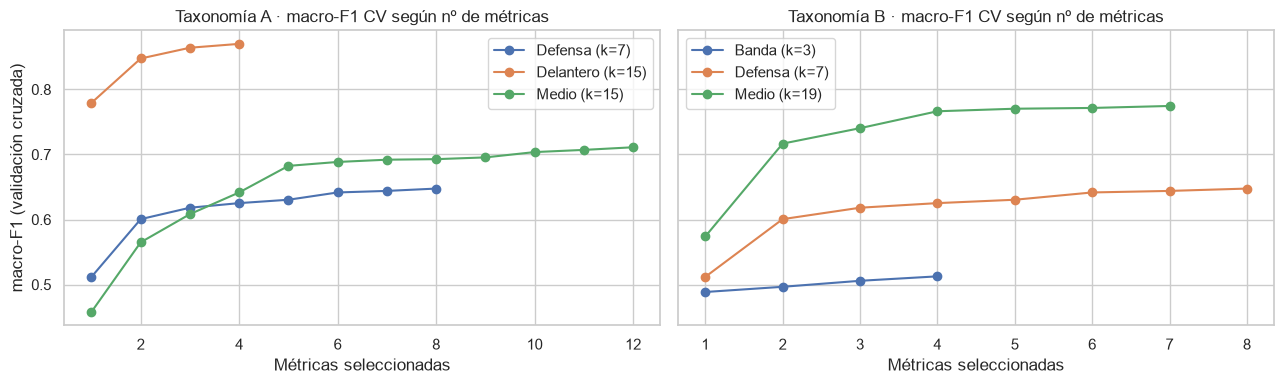

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (t, c) in zip(axes, cascadas.items()):
    for b, m in c.nivel2_.items():
        if len(m.history_):
            ax.plot(range(1, len(m.history_) + 1), m.history_, marker="o", label=f"{b} (k={m.k_})")
    ax.set_title(f"Taxonomía {t} · macro-F1 CV según nº de métricas")
    ax.set_xlabel("Métricas seleccionadas")
    ax.legend()
axes[0].set_ylabel("macro-F1 (validación cruzada)")
plt.tight_layout()
plt.show()

In [6]:
print("Métricas seleccionadas, taxonomía B:")
display(sel[sel["taxonomía"] == "B"].drop(columns="taxonomía").reset_index(drop=True))

Métricas seleccionadas, taxonomía B:


,bloque,paso,métrica,macro-F1 acumulado
0,Banda,1,mentality_positioning,0.4886
1,Banda,2,mentality_aggression,0.4966
2,Banda,3,shooting,0.5058
3,Banda,4,defending,0.5126
4,Defensa,1,attacking_crossing,0.5118
5,Defensa,2,defending,0.6006
6,Defensa,3,mentality_vision,0.6181
7,Defensa,4,defending_standing_tackle,0.6252
8,Defensa,5,weight_kg,0.6304
9,Defensa,6,pace,0.6416


**Lectura:** una curva que se aplana rápido indica que pocas métricas bastan para ese bloque; una que sigue subiendo, que las posiciones del bloque se distinguen por muchos matices. Compara las métricas elegidas con tu intuición de fútbol (por ejemplo, ¿aparecen centros y velocidad para Extremo, o entradas y marcaje para Central?).

## 4. Modelos planos de referencia

Un solo clasificador sobre las 9 clases, sin cascada. Permite saber si la cascada aporta algo.

- **Plano Fisher + KNN:** con 9 clases, Fisher produce hasta 8 discriminantes.
- **Plano Random Forest:** un techo de referencia, sin proyección.

In [7]:
inicio = time.time()
curva_plano = curva_k_fisher(X_tr, y_tr, list(range(1, 52, 2)), seed=SEED)
k_plano = elegir_k(curva_plano)
plano_knn = FisherKNN(k=k_plano).fit(X_tr, y_tr)
plano_rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(X_tr, y_tr)
print(f"Plano Fisher + KNN: k = {k_plano} · tiempo total: {time.time() - inicio:.0f} s")

Plano Fisher + KNN: k = 9 · tiempo total: 15 s


## 5. Evaluación de extremo a extremo

Para cada jugador de prueba se obtiene una distribución de probabilidad sobre las 9 clases. Métricas:

- **top-m:** la posición principal está entre las m más probables.
- **log-loss:** penaliza probabilidades mal asignadas. Las probabilidades se acotan en `[0.001, 1]` y se renormalizan para que ninguna clase con probabilidad 0 produzca un valor infinito (el suavizado difiere del notebook 03, así que los log-loss no son comparables entre notebooks).
- **flexible top-1:** la clase predicha coincide con la de *cualquiera* de las posiciones del jugador.
- **probabilidad en sus posiciones:** masa de probabilidad media asignada a las clases correspondientes a todas sus posiciones.

In [8]:
def alinear(P, clases):
    # Reordena las columnas de P (en el orden `clases`) al orden común ORDEN
    return P[:, [list(clases).index(c) for c in ORDEN]]

# Máscara de clases correspondientes a todas las posiciones de cada jugador
def mascara_posiciones(texto):
    clases = {MAPA_CLASE[p.strip()] for p in str(texto).split(",") if p.strip() in MAPA_CLASE}
    return np.array([c in clases for c in ORDEN])

S = np.vstack(test_campo["player_positions"].apply(mascara_posiciones).to_numpy())
y_idx = np.array([ORDEN.index(c) for c in y_te])
n = len(y_idx)

def evaluar(P):
    orden = np.argsort(-P, axis=1)
    Pc = np.clip(P, 1e-3, 1.0)
    Pc = Pc / Pc.sum(axis=1, keepdims=True)
    return {
        "top-1": (orden[:, 0] == y_idx).mean(),
        "top-2": (orden[:, :2] == y_idx[:, None]).any(axis=1).mean(),
        "top-3": (orden[:, :3] == y_idx[:, None]).any(axis=1).mean(),
        "log-loss": -np.log(Pc[np.arange(n), y_idx]).mean(),
        "macro-F1": f1_score(y_idx, orden[:, 0], average="macro"),
        "flexible top-1": S[np.arange(n), orden[:, 0]].mean(),
        "prob. en sus posiciones": (P * S).sum(axis=1).mean(),
    }

probas = {}
for t, c in cascadas.items():
    probas[f"Cascada {t} · dura"] = c.predict_proba(X_te, ruta="dura")
    probas[f"Cascada {t} · suave"] = c.predict_proba(X_te, ruta="suave")
probas["Plano · Fisher + KNN"] = alinear(plano_knn.predict_proba(X_te), plano_knn.classes_)
probas["Plano · Random Forest"] = alinear(plano_rf.predict_proba(X_te), plano_rf.classes_)

resultados = pd.DataFrame({nombre: evaluar(P) for nombre, P in probas.items()}).T
display(resultados.round(4))

,top-1,top-2,top-3,log-loss,macro-F1,flexible top-1,prob. en sus posiciones
Cascada A · dura,0.6851,0.8234,0.8599,1.4443,0.5560,0.8172,0.7643
Cascada A · suave,0.6860,0.8675,0.9436,0.8883,0.5550,0.8175,0.7235
Cascada B · dura,0.6820,0.8142,0.8399,1.5554,0.5591,0.8148,0.7778
Cascada B · suave,0.6884,0.8635,0.9276,0.9712,0.5650,0.8191,0.7321
Plano · Fisher + KNN,0.7032,0.8617,0.9295,0.9808,0.5718,0.8353,0.7557
Plano · Random Forest,0.7320,0.8875,0.9531,0.7793,0.5844,0.8586,0.6987


**Lectura:**

- **Dura vs. suave** (misma cascada): mide cuánto aporta combinar probabilidades entre niveles. El enrutamiento suave debería mejorar sobre todo el log-loss y el top-2, porque un error del Nivel 1 deja de ser definitivo.
- **A vs. B:** ahora sí se comparan en igualdad de condiciones, porque las clases finales son las mismas.
- **Cascada vs. plano:** si la cascada no supera a los modelos planos, su valor está en la interpretabilidad (métricas distintas por bloque) y no en el rendimiento.
- **Random Forest:** referencia de techo para las 9 clases.

## 6. Acierto por posición

In [9]:
modelos_pos = ["Cascada A · suave", "Cascada B · suave", "Plano · Fisher + KNN", "Plano · Random Forest"]
pos = test_campo["posicion_principal"].to_numpy()

def por_posicion(P, m=1):
    orden = np.argsort(-P, axis=1)[:, :m]
    ok = (orden == y_idx[:, None]).any(axis=1)
    return pd.Series(ok).groupby(pos).mean()

top1 = pd.DataFrame({nombre: por_posicion(probas[nombre], 1) for nombre in modelos_pos})
top1.insert(0, "n", pd.Series(pos).value_counts())
top1.insert(1, "clase", pd.Series(y_te, index=None).groupby(pos).first())
print("Acierto top-1 por posición principal:")
display(top1.sort_values("Cascada A · suave").round(3))

top2 = pd.DataFrame({nombre: por_posicion(probas[nombre], 2) for nombre in modelos_pos})
top2.insert(0, "n", pd.Series(pos).value_counts())
print("Acierto top-2 por posición principal:")
display(top2.sort_values("Cascada A · suave").round(3))

Acierto top-1 por posición principal:


,n,clase,Cascada A · suave,Cascada B · suave,Plano · Fisher + KNN,Plano · Random Forest
RWB,60,Carrilero,0.067,0.083,0.017,0.017
LWB,53,Carrilero,0.075,0.094,0.075,0.019
RW,91,Extremo,0.110,0.187,0.165,0.121
LW,83,Extremo,0.169,0.241,0.181,0.108
CF,26,Delantero centro,0.192,0.308,0.308,0.269
CAM,210,Mediapunta,0.371,0.319,0.395,0.362
LM,191,Mediocampista de banda,0.497,0.529,0.534,0.675
CDM,304,Pivote,0.539,0.615,0.625,0.694
RM,189,Mediocampista de banda,0.587,0.487,0.545,0.646
RB,237,Lateral,0.772,0.776,0.768,0.814


Acierto top-2 por posición principal:


,n,Cascada A · suave,Cascada B · suave,Plano · Fisher + KNN,Plano · Random Forest
CF,26,0.385,0.385,0.423,0.346
RWB,60,0.433,0.533,0.500,0.633
LWB,53,0.528,0.566,0.623,0.642
RW,91,0.582,0.505,0.462,0.505
LW,83,0.627,0.530,0.578,0.542
CAM,210,0.681,0.652,0.652,0.686
LM,191,0.728,0.738,0.733,0.812
RM,189,0.762,0.735,0.709,0.810
CDM,304,0.898,0.908,0.901,0.964
RB,237,0.924,0.924,0.932,0.958


**Lectura:** las posiciones difíciles esperables son las fronterizas (Extremo, Mediocampista de banda, Carrilero). Un modelo con mejor top-2 que top-1 en esas posiciones respalda el enfoque probabilístico: no acierta siempre la etiqueta única, pero casi siempre la incluye entre sus dos opciones.

## 7. Calibración de la cascada

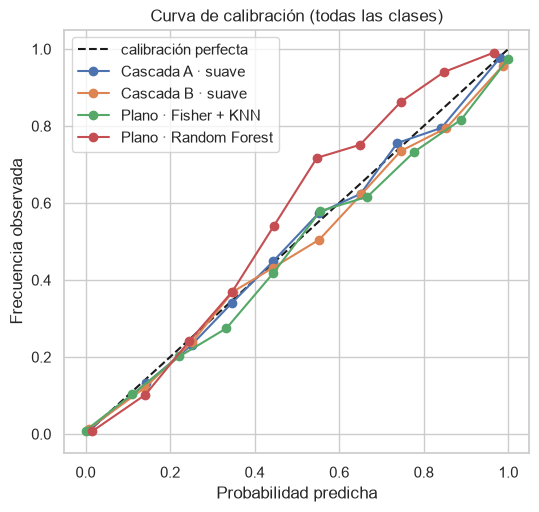

In [10]:
def curva_calibracion(P, bins=10):
    obs = (np.arange(P.shape[1])[None, :] == y_idx[:, None]).ravel().astype(float)
    p = P.ravel()
    cat = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    return (pd.DataFrame({"p": p, "obs": obs, "bin": cat})
              .groupby("bin").agg(p_media=("p", "mean"), frecuencia=("obs", "mean"), n=("obs", "size")))

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "k--", label="calibración perfecta")
for nombre in ["Cascada A · suave", "Cascada B · suave", "Plano · Fisher + KNN", "Plano · Random Forest"]:
    c = curva_calibracion(probas[nombre])
    ax.plot(c["p_media"], c["frecuencia"], marker="o", label=nombre)
ax.set_xlabel("Probabilidad predicha")
ax.set_ylabel("Frecuencia observada")
ax.set_title("Curva de calibración (todas las clases)")
ax.legend()
plt.show()

**Lectura:** las probabilidades de la cascada son productos de dos etapas; hay que comprobar que siguen calibradas. Una desviación sistemática indicaría que conviene recalibrar antes de interpretar un "60%" como tal.

## 8. Matriz de confusión de la mejor cascada

Cascada con menor log-loss: Cascada A · suave


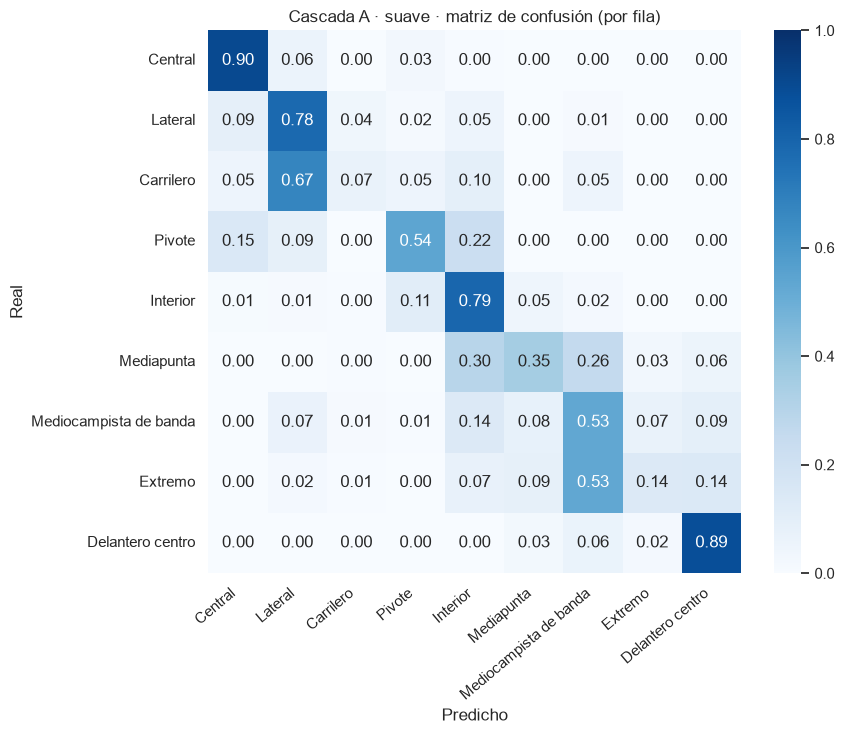

In [11]:
mejor = min(["Cascada A · suave", "Cascada B · suave"], key=lambda nombre: resultados.loc[nombre, "log-loss"])
print("Cascada con menor log-loss:", mejor)

pred = np.argmax(probas[mejor], axis=1)
cm = confusion_matrix(y_idx, pred, labels=range(len(ORDEN)), normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=ORDEN, yticklabels=ORDEN, ax=ax)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title(f"{mejor} · matriz de confusión (por fila)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## 9. Ejemplos de predicción

La salida del modelo es una distribución de probabilidad: las tres posiciones más probables de jugadores concretos de prueba, junto con las posiciones que figuran en el dataset.

In [12]:
P = probas[mejor]
rng = np.random.default_rng(SEED)
elegidos = []
for p in ["LW", "CAM", "CDM", "RWB", "CB", "ST"]:
    idx = np.where(pos == p)[0]
    if len(idx):
        elegidos.append(int(rng.choice(idx)))

filas = []
for i in elegidos:
    top = np.argsort(-P[i])[:3]
    filas.append({
        "jugador": test_campo.loc[i, "short_name"],
        "posiciones": test_campo.loc[i, "player_positions"],
        "predicción (top-3)": " · ".join(f"{ORDEN[j]} {P[i, j]:.0%}" for j in top),
    })
display(pd.DataFrame(filas))

,jugador,posiciones,predicción (top-3)
0,W. Jarvis,"LW, ST, RW",Extremo 45% · Delantero centro 39% · Mediocamp...
1,Yoon Min Ho,CAM,Mediocampista de banda 46% · Mediapunta 29% · ...
2,T. Kok,"CDM, CB",Pivote 50% · Interior 44% · Delantero centro 2%
3,C. O'Keeffe,"RWB, RM",Carrilero 37% · Lateral 28% · Mediocampista de...
4,D. Amartey,CB,Central 67% · Lateral 13% · Carrilero 13%
5,T. Klidje,ST,Delantero centro 70% · Mediocampista de banda ...


## 10. Evaluación con clases fusionadas

Sin reentrenar, se fusionan las clases ambiguas **sumando sus probabilidades** después de predecir: Lateral + Carrilero, y Mediocampista de banda + Extremo (→ Banda). Quedan 7 clases. Es la misma predicción del modelo, evaluada con una taxonomía más gruesa.

Precauciones al leer los resultados:

- Con menos clases, el azar acierta más (top-1 de azar: 1/9 → 1/7), así que las cifras de 9 y 7 clases **no se comparan en términos absolutos**, sino por cuánto separan a los modelos entre sí.
- Que el top-1 suba al fusionar es lo esperable, pero no está garantizado: sumar probabilidades puede cambiar cuál es la clase más probable.
- No equivale a reentrenar con 7 clases (por ejemplo, SFS y Fisher siguen optimizando sobre las 9).

In [13]:
# --- Evaluación con clases fusionadas (suma de probabilidades, sin reentrenar) ---
FUSION = {"Carrilero": "Lateral", "Extremo": "Banda", "Mediocampista de banda": "Banda"}
ORDEN7 = ["Central", "Lateral", "Pivote", "Interior", "Mediapunta", "Banda", "Delantero centro"]

# Matriz de fusión 9 -> 7 clases
M = np.zeros((len(ORDEN), len(ORDEN7)))
for i, c in enumerate(ORDEN):
    M[i, ORDEN7.index(FUSION.get(c, c))] = 1.0

y7 = M[y_idx].argmax(axis=1)           # etiqueta real fusionada
S7 = (S.astype(float) @ M) > 0         # clases fusionadas de todas las posiciones del jugador

def evaluar_fusion(P9):
    P = P9 @ M                          # suma de las probabilidades de las clases fusionadas
    orden = np.argsort(-P, axis=1)
    Pc = np.clip(P, 1e-3, 1.0)
    Pc = Pc / Pc.sum(axis=1, keepdims=True)
    return {
        "top-1": (orden[:, 0] == y7).mean(),
        "top-2": (orden[:, :2] == y7[:, None]).any(axis=1).mean(),
        "top-3": (orden[:, :3] == y7[:, None]).any(axis=1).mean(),
        "log-loss": -np.log(Pc[np.arange(n), y7]).mean(),
        "macro-F1": f1_score(y7, orden[:, 0], average="macro"),
        "flexible top-1": S7[np.arange(n), orden[:, 0]].mean(),
        "prob. en sus posiciones": (P * S7).sum(axis=1).mean(),
    }

resultados_7 = pd.DataFrame({nombre: evaluar_fusion(P) for nombre, P in probas.items()}).T
print("Clases fusionadas (7):")
display(resultados_7.round(4))

cols = ["top-1", "top-2", "log-loss", "flexible top-1"]
comparacion = pd.concat({"9 clases": resultados[cols], "7 clases (fusionadas)": resultados_7[cols]}, axis=1)
print("Comparación 9 vs. 7 clases:")
display(comparacion.round(4))

Clases fusionadas (7):


,top-1,top-2,top-3,log-loss,macro-F1,flexible top-1,prob. en sus posiciones
Cascada A · dura,0.7501,0.8887,0.9344,0.9993,0.7010,0.8737,0.8300
Cascada A · suave,0.7568,0.9227,0.9733,0.6542,0.7021,0.8786,0.7963
Cascada B · dura,0.7590,0.8442,0.8749,1.2904,0.7069,0.8822,0.8587
Cascada B · suave,0.7614,0.9267,0.9721,0.6555,0.7049,0.8844,0.8067
Plano · Fisher + KNN,0.7725,0.9206,0.9626,0.7011,0.7200,0.8948,0.8313
Plano · Random Forest,0.7958,0.9341,0.9798,0.5960,0.7422,0.9111,0.7728


Comparación 9 vs. 7 clases:


9 clases                                  \
                         top-1   top-2 log-loss flexible top-1   
Cascada A · dura        0.6851  0.8234   1.4443         0.8172   
Cascada A · suave       0.6860  0.8675   0.8883         0.8175   
Cascada B · dura        0.6820  0.8142   1.5554         0.8148   
Cascada B · suave       0.6884  0.8635   0.9712         0.8191   
Plano · Fisher + KNN    0.7032  0.8617   0.9808         0.8353   
Plano · Random Forest   0.7320  0.8875   0.7793         0.8586   

                      7 clases (fusionadas)                                  
                                      top-1   top-2 log-loss flexible top-1  
Cascada A · dura                     0.7501  0.8887   0.9993         0.8737  
Cascada A · suave                    0.7568  0.9227   0.6542         0.8786  
Cascada B · dura                     0.7590  0.8442   1.2904         0.8822  
Cascada B · suave                    0.7614  0.9267   0.6555         0.8844  
Plano · Fisher + KNN                 0.7725  0.9206   0.7011         0.8948  
Plano · Random Forest                0.7958  0.9341   0.5960         0.9111

In [14]:
def por_posicion_7(P9, m=1):
    orden = np.argsort(-(P9 @ M), axis=1)[:, :m]
    ok = (orden == y7[:, None]).any(axis=1)
    return pd.Series(ok).groupby(pos).mean()

top1_7 = pd.DataFrame({nombre: por_posicion_7(probas[nombre]) for nombre in modelos_pos})
top1_7.insert(0, "n", pd.Series(pos).value_counts())
top1_7.insert(1, "clase fusionada", pd.Series([ORDEN7[j] for j in y7]).groupby(pos).first())
print("Acierto top-1 por posición principal (7 clases):")
display(top1_7.sort_values("Cascada A · suave").round(3))

Acierto top-1 por posición principal (7 clases):


,n,clase fusionada,Cascada A · suave,Cascada B · suave,Plano · Fisher + KNN,Plano · Random Forest
CF,26,Delantero centro,0.192,0.308,0.269,0.192
CAM,210,Mediapunta,0.300,0.252,0.305,0.271
CDM,304,Pivote,0.510,0.605,0.592,0.671
LM,191,Banda,0.623,0.686,0.644,0.754
RM,189,Banda,0.667,0.672,0.651,0.735
LW,83,Banda,0.747,0.783,0.747,0.843
RW,91,Banda,0.747,0.692,0.725,0.791
CM,441,Interior,0.787,0.746,0.791,0.780
RWB,60,Lateral,0.800,0.867,0.850,0.867
RB,237,Lateral,0.852,0.848,0.823,0.840


In [15]:
from sklearn.metrics import roc_auc_score

P = probas["Cascada A · suave"]

# AUC uno-contra-resto por clase: ¿la clase real recibe más probabilidad que las demás,
# aunque no llegue a ser la más probable?
auc_ovr = {c: roc_auc_score(y_idx == i, P[:, i]) for i, c in enumerate(ORDEN)}
display(pd.Series(auc_ovr, name="AUC uno-contra-resto").round(3).to_frame())

# AUC por pares: entre jugadores de dos clases vecinas, ¿se ordenan bien?
def auc_par(a, b):
    ia, ib = ORDEN.index(a), ORDEN.index(b)
    m = np.isin(y_idx, [ia, ib])
    score = P[m, ia] / np.maximum(P[m, ia] + P[m, ib], 1e-12)
    return roc_auc_score(y_idx[m] == ia, score)

pares = [("Extremo", "Mediocampista de banda"), ("Carrilero", "Lateral"),
         ("Mediapunta", "Interior"), ("Pivote", "Interior")]
display(pd.DataFrame([{"par": f"{a} vs {b}", "AUC": auc_par(a, b)} for a, b in pares]).round(3))

,AUC uno-contra-resto
Central,0.978
Lateral,0.948
Carrilero,0.807
Pivote,0.952
Interior,0.949
Mediapunta,0.916
Mediocampista de banda,0.894
Extremo,0.888
Delantero centro,0.986


,par,AUC
0,Extremo vs Mediocampista de banda,0.647
1,Carrilero vs Lateral,0.594
2,Mediapunta vs Interior,0.904
3,Pivote vs Interior,0.903


## Conclusiones

- **Métricas elegidas por SFS:** coherentes con el rol de cada bloque. Defensa (A): crossing, defending, tackles, peso y pace (macro-F1 CV 0.648). Delantero (A): heading, crossing y strength (0.870). Medio (A): sliding tackle, finishing y sprint speed (0.711 con 12 métricas); sin las bandas (B) sube a 0.774 con 7 métricas.
- **Enrutamiento suave vs. duro:** el top-1 no cambia (A: 0.685 → 0.686; B: 0.682 → 0.688), pero mejora top-2 (A: 0.823 → 0.868), top-3 (0.860 → 0.944) y baja el log-loss casi 38% (A: 1.444 → 0.888; B: 1.555 → 0.971).
- **Taxonomía A vs. B:** empate dentro del ruido (error estándar del top-1 ≈ 0.8 puntos). A tiene mejor log-loss (0.888 vs 0.971) y top-3; B, algo mejor macro-F1.
- **Cascada vs. planos:** la cascada no supera a los modelos planos. Frente a Fisher + KNN plano pierde en top-1 (0.686 vs 0.703) y flexible (0.818 vs 0.835), y gana en top-3 y log-loss. El Random Forest plano es el mejor (top-1 0.732, flexible 0.859, log-loss 0.779). El valor de la cascada es la interpretabilidad.
- **Matriz de confusión (cascada A suave, 9 clases):** diagonal fuerte en Central (0.90), Delantero centro (0.89), Interior (0.79) y Lateral (0.78). Carrilero se clasifica como Lateral en el 67% de los casos (7% correcto) y Extremo como Mediocampista de banda en el 53% (14% correcto), mientras que el error inverso es mínimo (Lateral → Carrilero 4%; Mediocampista de banda → Extremo 7%): ante la duda, el modelo elige la clase más numerosa. Mediapunta se reparte entre Interior (30%) y Mediocampista de banda (26%), y Pivote entre Interior (22%) y los defensas (24%). Se observó una pequeña discrepancia entre ejecuciones del notebook (p. ej., CAM 0.371 vs 0.35), pendiente de verificar.
- **Posiciones más difíciles:** Carrilero (RWB/LWB top-1 ≈ 0.07-0.09; RF 0.02), Extremo (RW/LW 0.11-0.24; RF 0.11-0.12) y CAM (≈ 0.37-0.40). Ni el Random Forest las resuelve, por lo que el límite está en las etiquetas. El submodelo Banda de B (Extremo vs. Mediocampista de banda) llega a macro-F1 0.513, equivalente a azar (0.500). El top-2 rescata parte: RW 0.58, LW 0.63, CAM 0.68 en la cascada A.
- **Calibración:** las cascadas quedan casi sobre la diagonal; el KNN plano está algo sobreconfiado y el Random Forest, subconfiado.
- **Acierto flexible:** 0.818 (cascadas), 0.835 (KNN plano), 0.859 (Random Forest), frente a 0.686, 0.703 y 0.732 de top-1 estricto.
- **Decisiones y siguientes pasos:** se conservan las 9 clases, porque los roles son distintos y la salida probabilística ya expresa la ambigüedad. Se añade una evaluación con clases fusionadas (sumando probabilidades) para mostrar lo que los datos actuales sostienen. La Fase 3 debe replantearse: FBref retiró sus estadísticas avanzadas en enero de 2026, por lo que hay que elegir otra fuente que además tenga posiciones detalladas. Pendiente de explicar: la asimetría LB/RB en los modelos planos.
- **Evaluación con clases fusionadas (7):** al sumar probabilidades, el top-1 sube entre 6 y 8 puntos en todos los modelos (cascada A suave 0.686 → 0.757; B suave 0.688 → 0.761; KNN plano 0.703 → 0.773; Random Forest 0.732 → 0.796) y las brechas entre modelos casi no cambian. Banda (62-84%) y Lateral con Carrilero (80-91%) se reconocen bien: el modelo identifica la familia de rol, pero no el subrol. A cambio, CAM cae entre 7 y 9 puntos (≈ 0.25-0.31) en todos los modelos, probablemente absorbido por Banda (inferencia; falta revisar la matriz de confusión). Con 7 clases, la cascada suave supera al KNN plano en log-loss (0.654 vs 0.701) y top-3 (0.973 vs 0.963), y pierde en top-1 (0.757 vs 0.773); el Random Forest sigue siendo el mejor (top-1 0.796, log-loss 0.596).
- **AUC (cascada A suave):** uno-contra-resto entre 0.89 y 0.99 (Delantero centro 0.986, Central 0.978, Pivote 0.952, Interior 0.949, Lateral 0.948, Mediapunta 0.916, Mediocampista de banda 0.894, Extremo 0.888), con Carrilero como el más bajo (0.807). Por pares: Mediapunta vs. Interior 0.904 y Pivote vs. Interior 0.903, donde el modelo sí ordena bien y el bajo top-1 se debe al tamaño de las clases; Extremo vs. Mediocampista de banda 0.647 y Carrilero vs. Lateral 0.594 (error estándar ≈ 0.03), donde la información de los atributos es débil. Los errores de la matriz de confusión son de dos tipos: de prior (Mediapunta, Pivote) y de información (Extremo, Carrilero).